# TP3 Dataset « big » avec PySpark : images de vêtements (Outfit Items) - OZEL IBRAHIM

Même problème que le notebook `TP3_Outfit_Items_Images.ipynb` (reconnaître le type de vêtement sur une photo, 13 classes), mais ici **chaque étape est faite par Spark**, de façon distribuée.

Données : [Outfit Items (Kaggle)](https://www.kaggle.com/datasets/kritanjalijain/outfititems), **~50 000 images, ~7 Go**, déjà découpées en `train` / `val` / `test`.

**Pourquoi Spark** : la machine a 16 Go de RAM ; les images décodées pour le réseau prendraient environ 15 Go. Spark découpe le dataset en **partitions** (~64 Mo de fichiers chacune) traitées en parallèle par plusieurs cœurs, sans jamais tout charger en mémoire. Sur un cluster, le même code tournerait sur plusieurs machines en changeant seulement le `master`.

| Étape | Outil Spark |
|---|---|
| Chargement | DataFrame des chemins, les fichiers sont lus par les tâches Spark |
| EDA | UDF qui lit l'en-tête des images + `groupBy` / `agg` |
| Prétraitement | hash SHA-256 pour les doublons, `filter`, `StringIndexer`, échantillonnage par fenêtre |
| Transformation | `pandas_udf` qui fait passer chaque image dans MobileNetV2 pré-entraîné → vecteur de 1 280 valeurs |
| ML | `LogisticRegression` de **Spark MLlib**, réglage du paramètre sur le jeu `val` |
| Évaluation | `MulticlassClassificationEvaluator`, matrice de confusion |

## Contribution

**Le notebook s'exécute-t-il de bout en bout ?** Oui : toutes les cellules s'exécutent sans erreur (avec `IMAGES_PAR_CLASSE = 1000` pour un temps raisonnable sur CPU).

**Problèmes rencontrés**
- PySpark 4 a besoin de Java 17 ou plus, alors que le Java par défaut est un Java 8 : on utilise le JDK 21 de `~/.jdks`.
- Sous Windows, les workers Python mettent du temps à démarrer : il a fallu augmenter `spark.python.authenticate.socketTimeout` et forcer le réseau local (`spark.driver.host` = 127.0.0.1).
- Le nombre de cœurs est limité à 4, parce que chaque cœur charge son propre MobileNetV2 en mémoire.
- Le calcul des vecteurs (cellule `pandas_udf`) plantait avec « Python worker failed to connect back » : dans Spark 4.2, un worker Python a environ 10 s (valeur codée en dur, que `socketTimeout` ne change pas) pour se connecter, et sous Windows une machine chargée par TensorFlow dépasse parfois ce délai. En mode `local[4]` une tâche n'est jamais relancée, donc tout le job échouait. Corrections : `local[4,4]` (jusqu'à 4 essais par tâche) et TensorFlow limité à 3 threads par worker (`TF_NUM_INTRAOP_THREADS`). Quelques tâches échouent encore une fois puis passent au deuxième essai.
- Exécution complète : environ 1 h sur CPU, dont 52 min pour les vecteurs des 20 699 images.

**Modifications apportées**
- Version entièrement PySpark du notebook `TP3_Outfit_Items_Images.ipynb`.
- Détection des doublons par hash SHA-256, pour éviter qu'une même image soit à la fois dans train et dans test.
- Extraction de caractéristiques MobileNetV2 dans une `pandas_udf`, puis régression logistique Spark MLlib réglée sur le jeu `val`.
- `IMAGES_PAR_CLASSE` limite le nombre d'images pour que le notebook tourne en un temps raisonnable sur CPU.

## [Data]

## 1. Lancement de Spark

PySpark 4 a besoin de **Java 17 ou plus**. Le Java installé par défaut sur cette machine est un Java 8 : on pointe `JAVA_HOME` vers le JDK 21 téléchargé par IntelliJ (`~/.jdks`).

On utilise 4 cœurs et pas tous : chaque cœur fait tourner son propre réseau de neurones à l'étape de transformation, et 12 copies de TensorFlow ne tiendraient pas dans 16 Go de RAM.

In [1]:
import os, sys, time, io
from pathlib import Path
from typing import Iterator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ["PYSPARK_PYTHON"] = sys.executable          # les workers utilisent le même Python que le notebook
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
jdks = sorted(Path.home().glob(".jdks/*"))
if jdks:   # shortcut: prend le dernier JDK de ~/.jdks ; sinon définir JAVA_HOME à la main vers un Java >= 17
    os.environ["JAVA_HOME"] = str(jdks[-1])

from pyspark.sql import SparkSession, Window, functions as F
from pyspark import StorageLevel
from pyspark.ml.feature import StringIndexer
from pyspark.ml.functions import array_to_vector
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

CORES = 4
# TensorFlow dans chaque worker : 3 threads chacun, pour ne pas lancer ~48 threads sur 12 cœurs (machine saturée)
os.environ["TF_NUM_INTRAOP_THREADS"] = str(max(1, (os.cpu_count() or CORES) // CORES))
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
spark = (SparkSession.builder.master(f"local[{CORES},4]").appName("TP3 Outfit Items")   # ,4 = jusqu'à 4 essais par tâche (sous Windows un worker Python peut dépasser le délai de connexion de ~10 s)
         .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")   # réseau local seulement
         .config("spark.python.authenticate.socketTimeout", "120s")   # Windows : les workers Python mettent du temps à démarrer
         .config("spark.driver.memory", "6g")
         .config("spark.sql.files.maxPartitionBytes", str(64 * 1024**2))        # partitions de ~64 Mo de fichiers
         .config("spark.sql.execution.arrow.maxRecordsPerBatch", "64")          # 64 images à la fois vers Python
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sns.set_theme(style="whitegrid")
SEED = 42
print("Spark", spark.version, "| Java", spark.sparkContext._jvm.System.getProperty("java.version"), "| cœurs :", spark.sparkContext.defaultParallelism)

Spark 4.2.0 | Java 21.0.9 | cœurs : 4


## 2. Chargement

Si les images sont dans `data/outfit/` on les utilise, sinon elles sont téléchargées depuis Kaggle avec `kagglehub` (~7 Go, une seule fois, mis en cache).

Spark reçoit seulement la **liste des chemins** (quelques Mo). Les images elles-mêmes sont lues plus tard, **par les tâches Spark**, partition par partition, au moment d'une *action* (`count`, `show`…) : c'est l'**évaluation paresseuse**.

*Remarque* : sur un cluster Linux on utiliserait directement `spark.read.format("binaryFile")`. Sous Windows cette source a besoin des binaires natifs de Hadoop (`winutils.exe`, `hadoop.dll`) ; en passant les chemins, le notebook marche sans eux.

In [2]:
DATA_DIR = Path("data/outfit")
if not any(DATA_DIR.rglob("*.png")):
    %pip install -q kagglehub
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("kritanjalijain/outfititems"))
print("Images lues depuis :", DATA_DIR.resolve())

EXTS = {".png", ".jpg", ".jpeg"}
fichiers = []
for p in DATA_DIR.resolve().rglob("*"):
    if p.suffix.lower() in EXTS:
        # .../train/train/upperwear/shirt/x.png -> split, catégorie, classe
        fichiers.append((str(p), p.parts[-4].lower(), p.parts[-3].lower(), p.parts[-2].lower(), p.stat().st_size))

imgs = (spark.createDataFrame(fichiers, "path string, split string, categorie string, classe string, length long")
             .repartition(CORES * 16))   # ~60 partitions de ~800 images : le travail est réparti entre les cœurs
imgs.printSchema()
print(len(fichiers), "fichiers | partitions :", imgs.rdd.getNumPartitions())

Note: you may need to restart the kernel to use updated packages.


Images lues depuis : C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\outfititems\versions\1


root
 |-- path: string (nullable = true)
 |-- split: string (nullable = true)
 |-- categorie: string (nullable = true)
 |-- classe: string (nullable = true)
 |-- length: long (nullable = true)



49934 fichiers | partitions : 64


## [EDA]

## 3. EDA distribuée

Une seule lecture complète des ~7 Go : pour chaque image on calcule en parallèle
- son **hash SHA-256** (pour trouver les doublons à l'étape suivante),
- ses **dimensions et son mode couleur** avec une UDF Python qui ne lit que l'en-tête de l'image (`Image.open` ne décode pas les pixels).

Le résultat ne contient plus les octets des images : quelques Mo seulement, qu'on garde en cache (`persist`) pour toutes les analyses suivantes.

In [3]:
@F.udf("struct<hash:string,largeur:int,hauteur:int,mode:string>")
def entete(path):
    import hashlib
    from PIL import Image
    with open(path, "rb") as f:
        contenu = f.read()
    h = hashlib.sha256(contenu).hexdigest()
    try:
        im = Image.open(io.BytesIO(contenu))
        return (h, im.width, im.height, im.mode)
    except Exception:
        return (h, None, None, None)   # fichier illisible

t = time.time()
meta = (imgs.select("path", "split", "categorie", "classe", "length", entete("path").alias("e"))
            .select("*", "e.*").drop("e")
            .persist(StorageLevel.MEMORY_AND_DISK))
n = meta.count()
print(f"{n} images lues et analysées en {time.time() - t:.0f} s")
meta.show(5, truncate=40)

49934 images lues et analysées en 115 s


+----------------------------------------+-----+---------+------+------+----------------------------------------+-------+-------+----+
|                                    path|split|categorie|classe|length|                                    hash|largeur|hauteur|mode|
+----------------------------------------+-----+---------+------+------+----------------------------------------+-------+-------+----+
|C:\Users\zelof\.cache\kagglehub\datas...|train|upperwear|jacket|163804|7821a742c6fb378661ccb969bac07ad7926f8...|    480|    640| RGB|
|C:\Users\zelof\.cache\kagglehub\datas...|train|upperwear|jacket|288447|2e7e5e2dbfd23ca25e6d56830dee105f60f1d...|    480|    640| RGB|
|C:\Users\zelof\.cache\kagglehub\datas...|train|upperwear|jacket|449920|daf71e9673f91ead0c805a3de3112cea6e31c...|    480|    640| RGB|
|C:\Users\zelof\.cache\kagglehub\datas...|train|upperwear|jacket|304559|66cab1b05ea65ae672a9a1828f256cba575bb...|    480|    640| RGB|
|C:\Users\zelof\.cache\kagglehub\datas...|train|upperwe

In [4]:
meta.groupBy("split").count().orderBy("split").show()
par_classe = (meta.groupBy("categorie", "classe").pivot("split").count()
                  .orderBy("categorie", "classe").toPandas().set_index(["categorie", "classe"]))
par_classe

+-----+-----+
|split|count|
+-----+-----+
| test| 5011|
|train|40139|
|  val| 4784|
+-----+-----+



test  train  val
categorie   classe                    
accessories bag        399   3184  398
            hat        262   2125  249
bottomwear  pants      476   3929  432
            shorts     453   3574  421
            skirt      384   3079  370
footwear    flats      434   3465  433
            heels      434   3464  433
            shoes      189   1507  188
            sneakers   440   3512  439
one-piece   dress      359   2953  342
upperwear   jacket     331   2510  290
            shirt      416   3406  389
            tshirt     434   3431  400

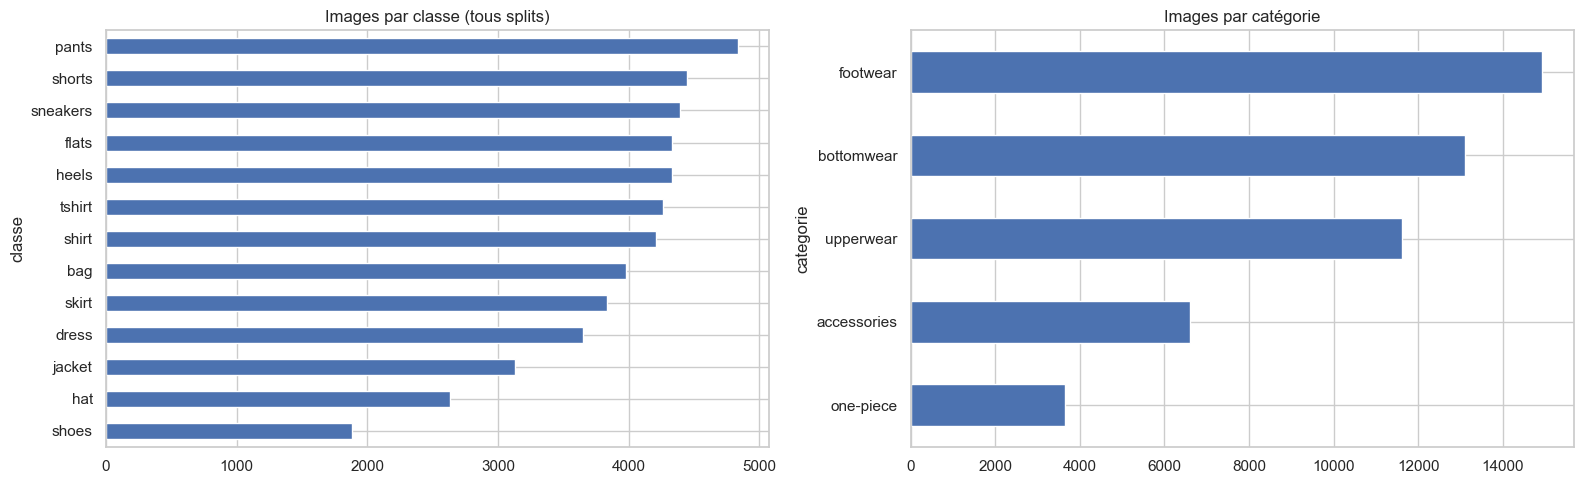

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
par_classe.sum(axis=1).droplevel(0).sort_values().plot.barh(ax=ax[0], title="Images par classe (tous splits)")
par_classe.groupby(level=0).sum().sum(axis=1).sort_values().plot.barh(ax=ax[1], title="Images par catégorie")
plt.tight_layout(); plt.show()

In [6]:
meta.groupBy("mode").count().orderBy(F.desc("count")).show()
meta.select(F.min("largeur"), F.max("largeur"), F.avg("largeur"), F.min("hauteur"), F.max("hauteur"), F.avg("hauteur"),
            (F.sum("length") / 1024**3).alias("total_Go")).show()
meta.groupBy("categorie").agg(F.round(F.avg("length") / 1024, 1).alias("taille_moy_Ko"),
                              F.round(F.avg(F.col("largeur") / F.col("hauteur")), 2).alias("ratio_moy")).show()

+----+-----+
|mode|count|
+----+-----+
| RGB|49933|
|   L|    1|
+----+-----+



+------------+------------+------------------+------------+------------+-----------------+-----------------+
|min(largeur)|max(largeur)|      avg(largeur)|min(hauteur)|max(hauteur)|     avg(hauteur)|         total_Go|
+------------+------------+------------------+------------+------------+-----------------+-----------------+
|         225|         888|469.20523090479435|         257|         936|624.8779188528858|6.540440829470754|
+------------+------------+------------------+------------+------------+-----------------+-----------------+



+-----------+-------------+---------+
|  categorie|taille_moy_Ko|ratio_moy|
+-----------+-------------+---------+
|  one-piece|        153.5|     0.75|
| bottomwear|        144.5|     0.75|
|  upperwear|        161.0|     0.75|
|accessories|        148.0|     0.75|
|   footwear|        104.0|     0.76|
+-----------+-------------+---------+



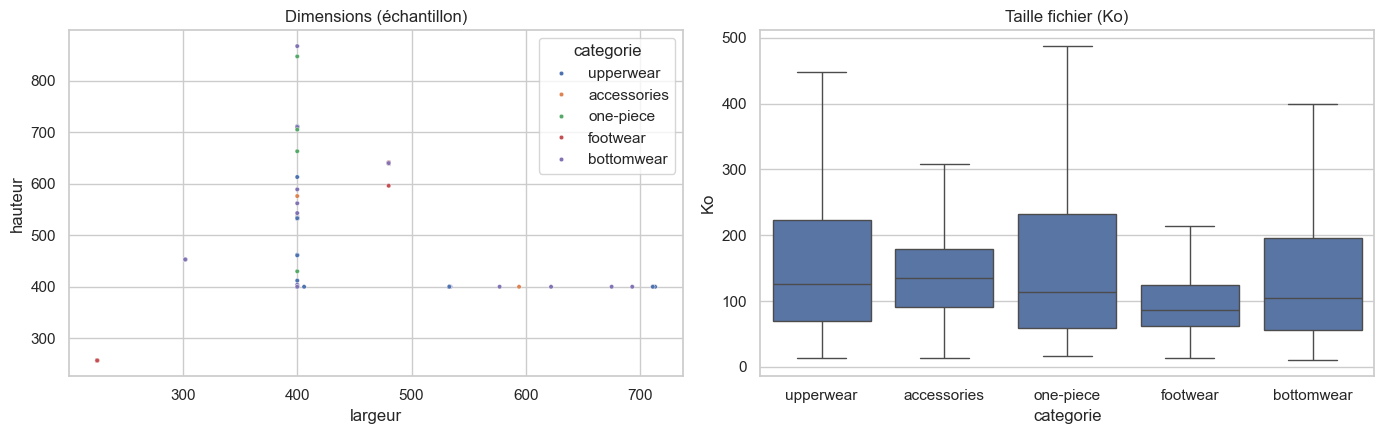

In [7]:
# Les graphiques se font sur un petit échantillon ramené dans pandas (toPandas ne ramène que ce qu'on lui demande)
ech = meta.sample(fraction=min(1.0, 3000 / n), seed=SEED).select("categorie", "largeur", "hauteur", "length").toPandas()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=ech, x="largeur", y="hauteur", hue="categorie", s=10, ax=ax[0]).set_title("Dimensions (échantillon)")
sns.boxplot(data=ech, x="categorie", y=ech["length"] / 1024, ax=ax[1], showfliers=False).set(title="Taille fichier (Ko)", ylabel="Ko")
plt.tight_layout(); plt.show()

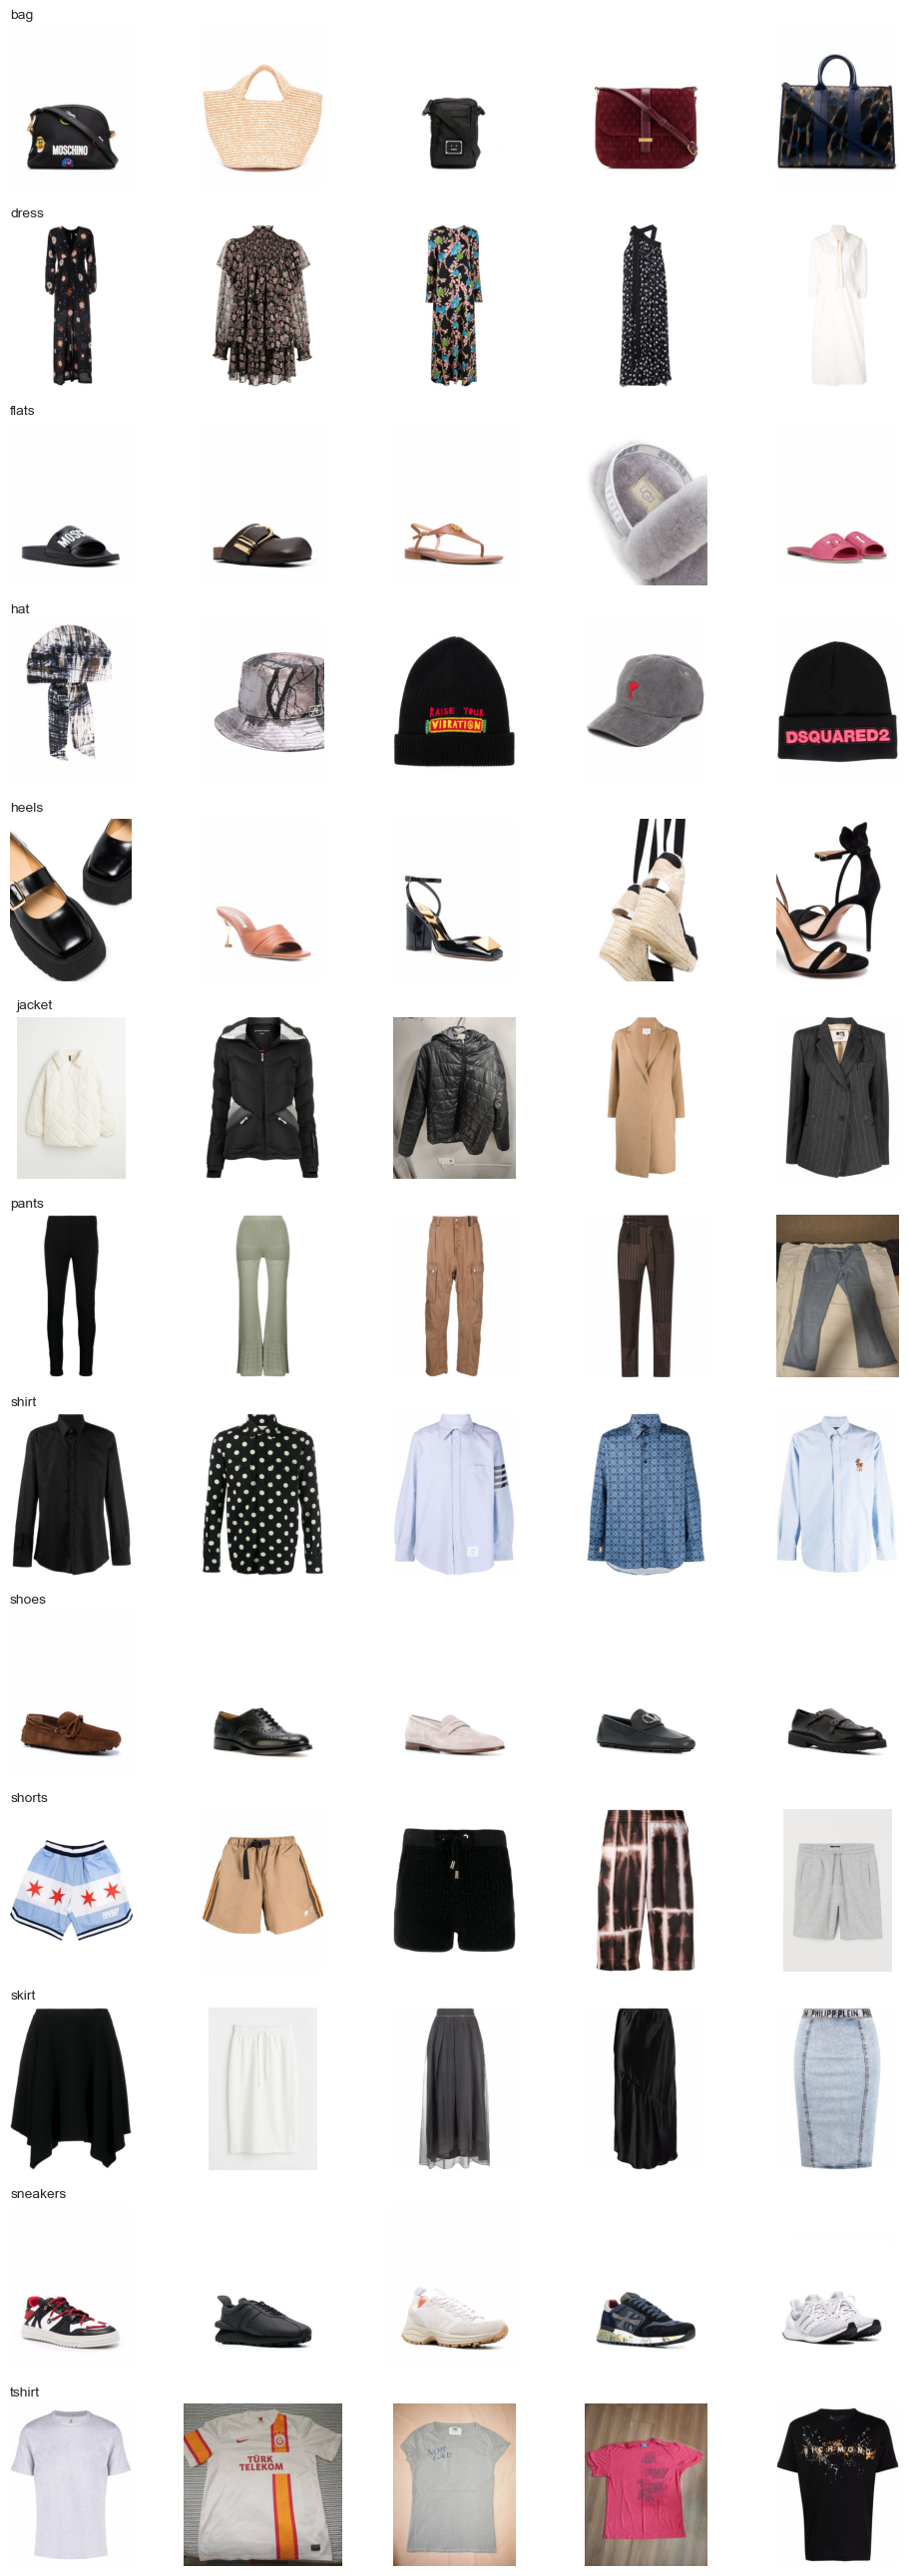

In [8]:
from PIL import Image
exemples = (meta.withColumn("r", F.row_number().over(Window.partitionBy("classe").orderBy(F.rand(SEED))))
                .filter("r <= 5").select("classe", "path").toPandas())
classes_ex = sorted(exemples["classe"].unique())
fig, axes = plt.subplots(len(classes_ex), 5, figsize=(10, 2 * len(classes_ex)))
for i, c in enumerate(classes_ex):
    for j, p in enumerate(exemples[exemples["classe"] == c]["path"]):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
    for a in axes[i]: a.axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## [Prétraitement]

## 4. Prétraitement

1. **Images illisibles** : l'UDF a renvoyé `null` → on les retire.
2. **Doublons** : deux fichiers avec le même hash ont exactement le même contenu. Une image présente à la fois dans `train` et dans `test` fausserait l'évaluation (le modèle l'aurait déjà vue) : c'est une **fuite de données**. On ne garde qu'une copie de chaque image.
3. **Étiquettes** : `StringIndexer` transforme chaque classe en numéro (0 = la plus fréquente).
4. **Échantillonnage** (optionnel) : `IMAGES_PAR_CLASSE` limite le nombre d'images par classe et par split pour réduire le temps de calcul sur CPU. `None` = tout le dataset.

In [9]:
print("Illisibles :", meta.filter(F.col("largeur").isNull()).count())

doublons = meta.groupBy("hash").agg(F.count("*").alias("n"), F.countDistinct("split").alias("nb_splits"),
                                    F.countDistinct("classe").alias("nb_classes")).filter("n > 1")
doublons.agg(F.count("*").alias("groupes_de_doublons"), F.sum(F.col("n") - 1).alias("fichiers_en_trop"),
             F.sum((F.col("nb_splits") > 1).cast("int")).alias("entre_splits_differents"),
             F.sum((F.col("nb_classes") > 1).cast("int")).alias("avec_classes_differentes")).show()

# Une seule copie par hash ; on garde de préférence celle du train
ordre_split = F.when(F.col("split") == "train", 0).when(F.col("split") == "val", 1).otherwise(2)
propre = (meta.filter(F.col("largeur").isNotNull())
              .withColumn("r", F.row_number().over(Window.partitionBy("hash").orderBy(ordre_split, "path")))
              .filter("r = 1").drop("r"))
print("Images gardées :", propre.count(), "sur", n)

Illisibles : 0


+-------------------+----------------+-----------------------+------------------------+
|groupes_de_doublons|fichiers_en_trop|entre_splits_differents|avec_classes_differentes|
+-------------------+----------------+-----------------------+------------------------+
|               1445|            5469|                    561|                       5|
+-------------------+----------------+-----------------------+------------------------+



Images gardées : 44465 sur 49934


In [10]:
IMAGES_PAR_CLASSE = 1000   # None = tout le dataset (~50 000 images, plusieurs heures sur CPU)

if IMAGES_PAR_CLASSE:
    propre = (propre.withColumn("r", F.row_number().over(Window.partitionBy("split", "classe").orderBy(F.rand(SEED))))
                    .filter(F.col("r") <= IMAGES_PAR_CLASSE).drop("r"))

indexer = StringIndexer(inputCol="classe", outputCol="label").fit(propre)
CLASSES = indexer.labels
propre = indexer.transform(propre).select("path", "split", "categorie", "classe", "label").persist()
propre.groupBy("split").count().orderBy("split").show()
print(len(CLASSES), "classes :", CLASSES)

+-----+-----+
|split|count|
+-----+-----+
| test| 4317|
|train|12246|
|  val| 4136|
+-----+-----+

13 classes : ['flats', 'sneakers', 'tshirt', 'pants', 'bag', 'shorts', 'shirt', 'skirt', 'dress', 'jacket', 'hat', 'shoes', 'heels']


## [Transformation]

## 5. Transformation : extraction de caractéristiques distribuée

Chaque image est transformée en un **vecteur de 1 280 nombres** par MobileNetV2 pré-entraîné sur ImageNet (sans sa dernière couche, avec une moyenne spatiale à la fin). Ce vecteur résume ce que contient l'image (formes, textures, couleurs) ; deux vêtements du même type ont des vecteurs proches.

Pour chaque image : décodage → conversion RVB → redimensionnement à 160 × 160 en gardant les proportions (bandes noires) → normalisation dans [-1, 1] → passage dans le réseau.

C'est une **`pandas_udf` en mode itérateur** : chaque tâche Spark charge le réseau **une fois**, puis reçoit les chemins par lots de 64 (via Apache Arrow), lit et transforme les images correspondantes, et renvoie les vecteurs. Les 4 cœurs travaillent en même temps sur des partitions différentes ; seule une partition d'images est en mémoire par cœur.

In [11]:
IMG = 160
import tensorflow as tf
tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, pooling="avg")   # télécharge les poids une fois avant que les workers en aient besoin

@F.pandas_udf("array<float>")
def embedding(chemins: Iterator[pd.Series]) -> Iterator[pd.Series]:
    import tensorflow as tf
    from PIL import Image, ImageOps
    modele = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, pooling="avg")
    for lot in chemins:
        images, ok = [], []
        for p in lot:
            try:
                images.append(np.asarray(ImageOps.pad(Image.open(p).convert("RGB"), (IMG, IMG))))
                ok.append(True)
            except Exception:
                ok.append(False)
        sortie = [None] * len(lot)
        if images:
            x = tf.keras.applications.mobilenet_v2.preprocess_input(np.stack(images).astype("float32"))
            vecteurs = iter(modele(x, training=False).numpy())
            sortie = [next(vecteurs) if o else None for o in ok]
        yield pd.Series(sortie)

t = time.time()
feats = (propre.repartition(CORES * 4)   # répartit les images gardées entre les cœurs
             .select("split", "classe", "categorie", "label", embedding("path").alias("emb"))
             .filter(F.col("emb").isNotNull())
             .select("split", "classe", "categorie", "label", array_to_vector("emb").alias("features"))
             .persist(StorageLevel.MEMORY_AND_DISK))
print(f"{feats.count()} vecteurs calculés en {time.time() - t:.0f} s")
feats.show(3, truncate=60)

20699 vecteurs calculés en 3136 s


+-----+--------+---------+-----+------------------------------------------------------------+
|split|  classe|categorie|label|                                                    features|
+-----+--------+---------+-----+------------------------------------------------------------+
|  val|sneakers| footwear|  1.0|[0.0,0.0,0.060144100338220596,0.0,0.03677351772785187,0.0...|
|  val|sneakers| footwear|  1.0|[0.0,0.0,0.0,1.9228787422180176,0.43721094727516174,0.010...|
|  val|sneakers| footwear|  1.0|[0.0,0.0,0.0,0.4012775421142578,0.0,0.3168933093547821,1....|
+-----+--------+---------+-----+------------------------------------------------------------+
only showing top 3 rows


Les vecteurs sont gardés en cache (`MEMORY_AND_DISK` : en mémoire, et sur disque si la mémoire manque), donc l'étape coûteuse n'est faite qu'une fois.

Sur un vrai cluster on les écrirait en **Parquet** (`feats.write.parquet(...)`) pour les réutiliser plus tard ; sous Windows, Spark a besoin de `winutils.exe` pour écrire des fichiers, d'où le cache.

## [ML]

## 6. Modélisation avec Spark MLlib

Régression logistique multinomiale (13 classes) sur les vecteurs. Le paramètre de régularisation `regParam` (qui limite le sur-apprentissage) est choisi sur le jeu **`val`** ; le jeu `test` ne sert qu'à l'évaluation finale.

In [12]:
train = feats.filter("split = 'train'")
val = feats.filter("split = 'val'")
test = feats.filter("split = 'test'")
ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

essais = []
for reg in [0.001, 0.01, 0.1]:
    t = time.time()
    m = LogisticRegression(maxIter=200, regParam=reg, elasticNetParam=0.0, family="multinomial").fit(train)
    p = m.transform(val)
    essais.append({"regParam": reg, "modele": m,
                   "accuracy_val": ev.evaluate(p, {ev.metricName: "accuracy"}),
                   "f1_val": ev.evaluate(p, {ev.metricName: "f1"}),
                   "accuracy_train": ev.evaluate(m.transform(train), {ev.metricName: "accuracy"}),
                   "secondes": round(time.time() - t)})
res = pd.DataFrame(essais).drop(columns="modele")
best = max(essais, key=lambda e: e["f1_val"])
print("Meilleur regParam :", best["regParam"])
res

Meilleur regParam : 0.01


,regParam,accuracy_val,f1_val,accuracy_train,secondes
0,0.001,0.917311,0.918152,0.999918,124
1,0.010,0.923839,0.924740,0.986690,75
2,0.100,0.916586,0.917320,0.941940,63


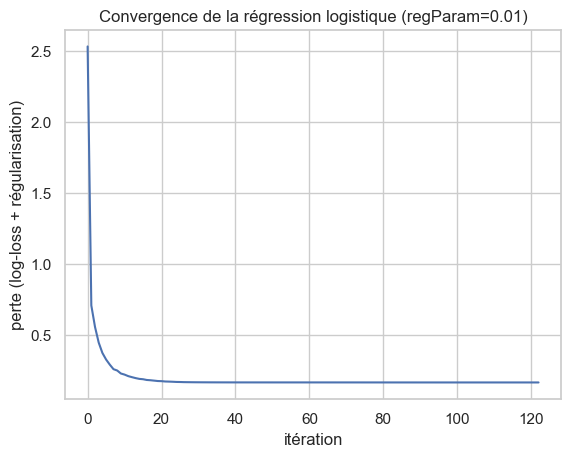

In [13]:
hist = best["modele"].summary.objectiveHistory
plt.plot(hist); plt.xlabel("itération"); plt.ylabel("perte (log-loss + régularisation)")
plt.title(f"Convergence de la régression logistique (regParam={best['regParam']})"); plt.show()

## [Éval]

## 7. Évaluation sur le jeu de test

- **Accuracy** : part d'images bien classées.
- **F1 pondéré**, **précision** et **rappel** : tiennent compte du déséquilibre des classes.
- **Matrice de confusion** : quelles classes sont confondues.

In [14]:
pred = best["modele"].transform(test).persist()
for metrique in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
    print(f"{metrique:>18} : {ev.evaluate(pred, {ev.metricName: metrique}):.3f}")

          accuracy : 0.915


                f1 : 0.916


 weightedPrecision : 0.918


    weightedRecall : 0.915


In [15]:
from sklearn.metrics import classification_report, confusion_matrix
pp = pred.select("label", "prediction", "categorie").toPandas()   # 1 ligne par image de test : petit
print(classification_report(pp["label"], pp["prediction"], labels=range(len(CLASSES)), target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

       flats      0.935     0.870     0.901       430
    sneakers      0.941     0.920     0.930       413
      tshirt      0.946     0.967     0.956       420
       pants      0.983     0.939     0.960       427
         bag      0.975     0.975     0.975       396
      shorts      0.896     0.904     0.900       408
       shirt      0.905     0.886     0.895       396
       skirt      0.851     0.848     0.850       363
       dress      0.930     0.924     0.927       357
      jacket      0.826     0.873     0.849       283
         hat      0.958     0.958     0.958       236
       shoes      0.821     0.923     0.869       169
       heels      0.421     0.842     0.561        19

    accuracy                          0.915      4317
   macro avg      0.876     0.910     0.887      4317
weighted avg      0.918     0.915     0.916      4317



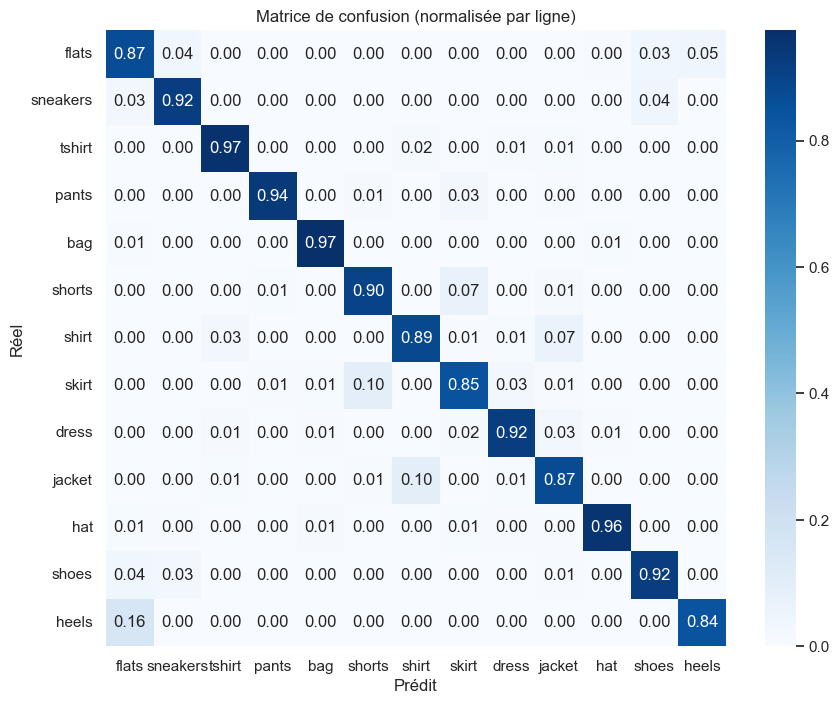

In [16]:
cm = confusion_matrix(pp["label"], pp["prediction"], labels=range(len(CLASSES)), normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion (normalisée par ligne)"); plt.show()

In [17]:
# Bonne catégorie (upperwear, footwear...) même si la sous-classe est fausse ?
cat_de = propre.select("classe", "categorie").distinct().toPandas().set_index("classe")["categorie"]
pp["cat_predite"] = [cat_de[CLASSES[int(i)]] for i in pp["prediction"]]
print(f"Accuracy sur la catégorie : {(pp['cat_predite'] == pp['categorie']).mean():.3f}")

Accuracy sur la catégorie : 0.978


In [18]:
spark.stop()

## [Conclusion]

## 8. Conclusion

- **Spark** a permis de traiter les ~7 Go d'images sans les charger en mémoire : lecture paresseuse des fichiers par les tâches Spark, calculs répartis par partitions sur plusieurs cœurs, seuls des résultats petits (statistiques, vecteurs) gardés en cache.
- **EDA** : une seule lecture distribuée donne tailles, dimensions, modes couleur et hash de chaque image.
- **Prétraitement** : le hash a permis de repérer les doublons, y compris entre train et test (fuite de données).
- **Transformation** : le réseau pré-entraîné, appliqué en parallèle via une `pandas_udf`, transforme chaque image en un vecteur de 1 280 valeurs.
- **ML** : une simple régression logistique de Spark MLlib sur ces vecteurs (meilleur `regParam` = 0,01) donne de bons résultats : accuracy **0,915** et F1 pondéré **0,916** sur le test, **0,978** au niveau des 5 catégories ; les erreurs restent surtout à l'intérieur d'une même catégorie (chaussures entre elles, hauts entre eux).
- La classe *heels* n'a que 19 images de test après suppression des doublons, ce qui rend son F1 (0,56) peu fiable.
- **Comparaison avec `TP3_Outfit_Items_Images.ipynb`** : le fine-tuning du réseau avec TensorFlow est plus précis (accuracy 0,939 contre 0,915), mais l'approche Spark se répartit naturellement sur un cluster : il suffit de changer `local[4]` par l'adresse du cluster.